### Installing required libraries

In [3]:
# Install required libraries
!pip install seaborn missingno xgboost catboost regex scikit-learn pandas numpy imblearn lightgbm polars


### Importing all libraries 

In [4]:
# Core libraries
import pandas as pd
import numpy as np
import csv
import re

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

# Preprocessing
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.utils import resample

# Model selection
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

# Models
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import LinearSVC
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import xgboost as xgb

# Metrics
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    make_scorer
)


### Import additional items as needed...

In [5]:
# Model selection utilities
from sklearn.model_selection import (
    KFold,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_score
)

# Preprocessing & pipelines
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import make_pipeline

# Models & balancing
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from imblearn.over_sampling import SMOTE

# Metrics (only those not already imported in Script 2)
from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    f1_score
)

# Plotly visualization
import plotly
import plotly.express as px
import plotly.graph_objs as go
import plotly.offline as py
from plotly.offline import iplot
from plotly.subplots import make_subplots
import plotly.figure_factory as ff

# Suppress warnings
import warnings
warnings.filterwarnings("ignore")


### Loading CSV data 

In [6]:
diabetes = pd.read_csv('raw/diabetic_data.csv')

# CLEANING AND TRANSFORMING THE DATASET

In [7]:
print(diabetes.columns)

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='str')


In [8]:
for g in diabetes['gender'].unique():
    col = f"Gender_{g}"
    diabetes[col] = (diabetes['gender'] == g).astype(int)


In [9]:
#@title AGE ENCODING
# Convert everything to string and strip spaces
diabetes['age'] = diabetes['age'].astype(str).str.strip()

# Mapping age ranges to numeric midpoint values
age_map = {
    '[0-10)': 5,
    '[10-20)': 15,
    '[20-30)': 25,
    '[30-40)': 35,
    '[40-50)': 45,
    '[50-60)': 55,
    '[60-70)': 65,
    '[70-80)': 75,
    '[80-90)': 85,
    '[90-100)': 95
}

# Apply mapping
diabetes['age'] = diabetes['age'].map(age_map)

In [11]:
# Mapping each admission_type_id to a category name
admission_type_map = {
    1: "emergency",
    2: "urgent",
    3: "elective",
    4: "newborn",
    5: "notavailable",
    6: "null",
    7: "trauma",
    8: "notmapped"
}

# Convert ID → category name
diabetes["admission_type"] = diabetes["admission_type_id"].map(admission_type_map)

# One-hot encode into separate binary columns
admission_dummies = pd.get_dummies(
    diabetes["admission_type"],
    prefix="admission"
)

# Convert any truthy values ("yes", "true", etc.) to 1, else 0
admission_dummies = admission_dummies.applymap(lambda x: 1 if x else 0)

# Add new columns to the dataframe
diabetes = pd.concat([diabetes, admission_dummies], axis=1)


AttributeError: 'DataFrame' object has no attribute 'applymap'

In [ ]:
# Mapping discharge_disposition_id → category name
discharge_disposition_map = {
    1: "home",
    2: "short_term_hospital",
    3: "snf",
    4: "icf",
    5: "other_inpatient",
    6: "home_health",
    7: "left_ama",
    8: "home_iv_care",
    9: "admitted_this_hospital",
    10: "neonate_another_hospital",
    11: "expired",
    12: "still_patient",
    13: "hospice_home",
    14: "hospice_facility",
    15: "swing_bed",
    16: "outpatient_other_institution",
    17: "outpatient_this_institution",
    18: "null",
    19: "expired_home_medicaid",
    20: "expired_facility_medicaid",
    21: "expired_unknown_medicaid",
    22: "rehab_facility",
    23: "long_term_care_hospital",
    24: "medicaid_nursing_facility",
    25: "not_mapped",
    27: "federal_healthcare_facility",
    28: "psychiatric_hospital",
    29: "critical_access_hospital",
    30: "other_healthcare_institution"
}

# Convert ID → category name
diabetes["discharge_type"] = diabetes["discharge_disposition_id"].map(discharge_disposition_map)

# One-hot encode into separate binary columns
discharge_dummies = pd.get_dummies(
    diabetes["discharge_type"],
    prefix="discharge"
)

# Convert any truthy values ("yes", "true", non-zero) to 1, else 0
discharge_dummies = discharge_dummies.applymap(lambda x: 1 if x else 0)

# Add new columns to the dataframe
diabetes = pd.concat([diabetes, discharge_dummies], axis=1)


In [ ]:
def icd_to_chapter(code):
    # Handle missing or non-numeric codes
    try:
        code = float(code)
    except:
        return "Unknown"

    if 1 <= code <= 139:
        return "Infectious and Parasitic Diseases"
    elif 140 <= code <= 239:
        return "Neoplasms"
    elif 240 <= code <= 279:
        return "Endocrine/Metabolic"
    elif 280 <= code <= 289:
        return "Blood Diseases"
    elif 290 <= code <= 319:
        return "Mental Disorders"
    elif 320 <= code <= 389:
        return "Nervous System"
    elif 390 <= code <= 459:
        return "Circulatory System"
    elif 460 <= code <= 519:
        return "Respiratory System"
    elif 520 <= code <= 579:
        return "Digestive System"
    elif 580 <= code <= 629:
        return "Genitourinary System"
    elif 630 <= code <= 679:
        return "Pregnancy/Childbirth"
    elif 680 <= code <= 709:
        return "Skin/Subcutaneous"
    elif 710 <= code <= 739:
        return "Musculoskeletal"
    elif 740 <= code <= 759:
        return "Congenital Anomalies"
    elif 760 <= code <= 779:
        return "Perinatal Conditions"
    elif 780 <= code <= 799:
        return "Symptoms/Ill-defined"
    elif 800 <= code <= 999:
        return "Injury/Poisoning"
    elif code >= 1000:
        return "Unknown"
    else:
        return "Unknown"


In [ ]:
for col in ["diag_1", "diag_2", "diag_3"]:
    diabetes[col + "_chapter"] = diabetes[col].apply(icd_to_chapter)


In [ ]:
# Mapping ICD chapter names to clean category labels
diag_chapter_map = {
    "Endocrine/Metabolic": "endocrine_metabolic",
    "Circulatory System": "circulatory",
    "Respiratory System": "respiratory",
    "Neoplasms": "neoplasms",
    "Infectious and Parasitic Diseases": "infectious_parasitic",
    "Injury/Poisoning": "injury_poisoning",
    "Genitourinary System": "genitourinary",
    "Nervous System": "nervous_system",
    "Blood Diseases": "blood_diseases",
    "Mental Disorders": "mental_disorders",
    "Symptoms/Ill-defined": "symptoms_ill_defined",
    "Skin/Subcutaneous": "skin_subcutaneous",
    "Musculoskeletal": "musculoskeletal",
    "Digestive System": "digestive",
    "Pregnancy/Childbirth": "pregnancy_childbirth",
    "Congenital Anomalies": "congenital_anomalies",
    "V-Codes": "v_codes",
    "E-Codes": "e_codes",
    "Unknown": "unknown"
}

# Apply mapping to each diagnosis column
for col in ["diag_1_chapter", "diag_2_chapter", "diag_3_chapter"]:
    diabetes[col] = diabetes[col].map(diag_chapter_map)

# One-hot encode all three diagnosis chapter columns
diag_dummies = pd.get_dummies(
    diabetes[["diag_1_chapter", "diag_2_chapter", "diag_3_chapter"]],
    prefix=["diag1", "diag2", "diag3"]
)

# Convert any truthy values ("yes", "true", non-zero) to 1, else 0
diag_dummies = diag_dummies.applymap(lambda x: 1 if x else 0)

# Add new columns to the dataframe
diabetes = pd.concat([diabetes, diag_dummies], axis=1)


AttributeError: 'DataFrame' object has no attribute 'applymap'

In [ ]:
#@title DIABEST MEDICATION ENCODING
# replacing No with 0 and Yes with 1 for if the patient has diabetic medications or not
diabetes['diabetesMed'] = diabetes['diabetesMed'].apply(
    lambda x: 1 if str(x).strip().lower() == "yes" else 0
)

In [ ]:
#@title READMITTED ENCODING
# Created indicator column for readmission within 30 days
# lessthan30 = 1 if readmitted is "<30", else 0

diabetes['lessthan30'] = (diabetes['readmitted'] == '<30').astype(int)

In [ ]:
#@title RACE ENCODING
# Replace '?' with 'Unknown'
diabetes['race'] = diabetes['race'].replace('?', 'Unknown')

# Create binary columns for each race category
for race in diabetes['race'].unique():
    col_name = f"Race_{race}"
    diabetes[col_name] = (diabetes['race'] == race).astype(int)


In [ ]:
diabetes.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital',
       ...
       'diag3_skin_subcutaneous', 'diag3_symptoms_ill_defined',
       'diag3_unknown', 'lessthan30', 'Race_Caucasian', 'Race_AfricanAmerican',
       'Race_Unknown', 'Race_Other', 'Race_Asian', 'Race_Hispanic'],
      dtype='str', length=150)

In [ ]:
import random

# -----------------------------
# 1. Conversion functions
# -----------------------------

def convert_weight(value):
    if pd.isna(value) or value == "None":
        return None
    
    value = str(value)

    if value.startswith('>'):
        return random.randint(201, 250)

    if '-' in value:
        clean = value.replace('(', '').replace(')', '')
        low, high = clean.split('-')
        return int(high)

    return None


def convert_glucose(value):
    if pd.isna(value) or value == "None":
        return None
    
    value = str(value)

    if value.startswith('>'):
        threshold = int(value[1:])
        return random.randint(threshold + 1, threshold + 50)

    if value == "Norm":
        return random.randint(70, 99)

    return None


def convert_a1c(value):
    if pd.isna(value) or value == "None":
        return None
    
    value = str(value)

    if value.startswith('>'):
        threshold = float(value[1:])
        return round(random.uniform(threshold + 0.1, threshold + 1.0), 1)

    if value == "Norm":
        return round(random.uniform(4.0, 5.6), 1)

    return None


# -----------------------------
# 2. Apply conversions
# -----------------------------

diabetes['weight_num'] = diabetes['weight'].apply(convert_weight)
diabetes['max_glu_serum_num'] = diabetes['max_glu_serum'].apply(convert_glucose)
diabetes['A1Cresult_num'] = diabetes['A1Cresult'].apply(convert_a1c)


# -----------------------------
# 3. RANDOM IMPUTATION for NaN
# -----------------------------

# Random weight between 25 and 250
diabetes['weight_num'] = diabetes['weight_num'].apply(
    lambda x: x if not pd.isna(x) else random.randint(25, 250)
)

# Random glucose between 70 and 350
diabetes['max_glu_serum_num'] = diabetes['max_glu_serum_num'].apply(
    lambda x: x if not pd.isna(x) else random.randint(70, 350)
)

# Random A1C between 4.0 and 10.0
diabetes['A1Cresult_num'] = diabetes['A1Cresult_num'].apply(
    lambda x: x if not pd.isna(x) else round(random.uniform(4.0, 10.0), 1)
)


# -----------------------------
# 4. Verify no missing values
# -----------------------------

print(diabetes[['weight_num','max_glu_serum_num','A1Cresult_num']].isna().sum())


weight_num           0
max_glu_serum_num    0
A1Cresult_num        0
dtype: int64


In [ ]:
for col in diabetes.columns:
    print(col)

encounter_id
patient_nbr
race
gender
age
weight
admission_type_id
discharge_disposition_id
admission_source_id
time_in_hospital
payer_code
medical_specialty
num_lab_procedures
num_procedures
num_medications
number_outpatient
number_emergency
number_inpatient
diag_1
diag_2
diag_3
number_diagnoses
max_glu_serum
A1Cresult
metformin
repaglinide
nateglinide
chlorpropamide
glimepiride
acetohexamide
glipizide
glyburide
tolbutamide
pioglitazone
rosiglitazone
acarbose
miglitol
troglitazone
tolazamide
examide
citoglipton
insulin
glyburide-metformin
glipizide-metformin
glimepiride-pioglitazone
metformin-rosiglitazone
metformin-pioglitazone
change
diabetesMed
readmitted
Gender_Female
Gender_Male
Gender_Unknown/Invalid
admission_type
admission_elective
admission_emergency
admission_newborn
admission_notavailable
admission_notmapped
admission_null
admission_trauma
admission_urgent
discharge_type
discharge_admitted_this_hospital
discharge_expired
discharge_expired_facility_medicaid
discharge_expired_

In [ ]:
#@title drop 1 intial columns
# Dropping unnecessary columns due to high missing values and low relevance
cleandiabetes = diabetes.drop([
    'encounter_id', 'patient_nbr', 'race', 'gender', 'weight', 'max_glu_serum', 'A1Cresult',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'payer_code', 'medical_specialty', 'diag_1',
       'diag_2', 'diag_3', 'admission_type_id', 'diag_1_chapter', 'diag_2_chapter', 'diag_3_chapter',
       'discharge_disposition_id', 'admission_source_id',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'readmitted'
], axis=1)

In [ ]:
for col in cleandiabetes.columns:
    print(col)

age
time_in_hospital
num_lab_procedures
num_procedures
num_medications
number_outpatient
number_emergency
number_inpatient
number_diagnoses
diabetesMed
Gender_Female
Gender_Male
Gender_Unknown/Invalid
admission_type
admission_elective
admission_emergency
admission_newborn
admission_notavailable
admission_notmapped
admission_null
admission_trauma
admission_urgent
discharge_type
discharge_admitted_this_hospital
discharge_expired
discharge_expired_facility_medicaid
discharge_expired_home_medicaid
discharge_federal_healthcare_facility
discharge_home
discharge_home_health
discharge_home_iv_care
discharge_hospice_facility
discharge_hospice_home
discharge_icf
discharge_left_ama
discharge_long_term_care_hospital
discharge_medicaid_nursing_facility
discharge_neonate_another_hospital
discharge_not_mapped
discharge_null
discharge_other_inpatient
discharge_outpatient_other_institution
discharge_outpatient_this_institution
discharge_psychiatric_hospital
discharge_rehab_facility
discharge_short_term

In [ ]:
# printing contents of admission_emergency column to verify it exists and is correct
print(cleandiabetes['admission_emergency'].unique())    

[False  True]


In [ ]:
numerical = [ 'age' , 'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_emergency',
    'number_outpatient',
    'number_inpatient',
    'number_diagnoses','weight_num', 'max_glu_serum_num', 'A1Cresult_num' ]

### MISSING DATA

In [ ]:
def missing(df):
    missing_number = df.isnull().sum().sort_values(ascending=False)
    missing_percent = (df.isnull().sum() / df.isnull().count()).sort_values(ascending=False)
    missing_values = pd.concat([missing_number, missing_percent], axis=1,
                               keys=['Missing_Number', 'Missing_Percent'])
    return missing_values

In [ ]:
print("Missing Data in Sub1:")
display(missing(cleandiabetes))



Missing Data in Sub1:


,Missing_Number,Missing_Percent
age,0,0.0
time_in_hospital,0,0.0
num_lab_procedures,0,0.0
num_procedures,0,0.0
num_medications,0,0.0
...,...,...
Race_Asian,0,0.0
Race_Hispanic,0,0.0
weight_num,0,0.0
max_glu_serum_num,0,0.0


### CORRELATION

In [ ]:
#@title Correlation Matrices
print("Correlation Matrix for Sub1")
display(cleandiabetes[numerical].corr())

Correlation Matrix for Sub1


,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_emergency,number_outpatient,number_inpatient,number_diagnoses,weight_num,max_glu_serum_num,A1Cresult_num
age,1.000000,0.107515,0.020770,-0.030104,0.041847,-0.087291,0.023724,-0.042861,0.242597,-0.004670,-0.012067,-0.038591
time_in_hospital,0.107515,1.000000,0.318450,0.191472,0.466135,-0.009681,-0.008916,0.073623,0.220186,-0.005694,0.009075,0.001923
num_lab_procedures,0.020770,0.318450,1.000000,0.058066,0.268161,-0.002279,-0.007602,0.039231,0.152773,-0.015897,0.028576,0.015512
num_procedures,-0.030104,0.191472,0.058066,1.000000,0.385767,-0.038179,-0.024819,-0.066236,0.073734,-0.006071,0.005123,0.005704
num_medications,0.041847,0.466135,0.268161,0.385767,1.000000,0.013180,0.045197,0.064194,0.261526,0.000416,0.010086,0.000197
number_emergency,-0.087291,-0.009681,-0.002279,-0.038179,0.013180,1.000000,0.091459,0.266559,0.055539,0.009387,-0.006562,-0.000861
number_outpatient,0.023724,-0.008916,-0.007602,-0.024819,0.045197,0.091459,1.000000,0.107338,0.094152,-0.012927,-0.008147,0.000378
number_inpatient,-0.042861,0.073623,0.039231,-0.066236,0.064194,0.266559,0.107338,1.000000,0.104710,0.002020,0.003238,-0.002036
number_diagnoses,0.242597,0.220186,0.152773,0.073734,0.261526,0.055539,0.094152,0.104710,1.000000,-0.005291,0.007940,-0.021288
weight_num,-0.004670,-0.005694,-0.015897,-0.006071,0.000416,0.009387,-0.012927,0.002020,-0.005291,1.000000,-0.005226,0.003845


In [ ]:
print("Correlation for lessthan30 grouped by readmit_less_30")
display(cleandiabetes.groupby('lessthan30')[numerical].corr())


Correlation for lessthan30 grouped by readmit_less_30


age  time_in_hospital  num_lab_procedures  \
lessthan30                                                                      
0          age                 1.000000          0.110387            0.023671   
           time_in_hospital    0.110387          1.000000            0.317989   
           num_lab_procedures  0.023671          0.317989            1.000000   
           num_procedures     -0.030476          0.184408            0.052895   
           num_medications     0.045641          0.463444            0.263560   
           number_emergency   -0.073727         -0.003926            0.004755   
           number_outpatient   0.025838         -0.008024           -0.009675   
           number_inpatient   -0.012445          0.081368            0.044145   
           number_diagnoses    0.250573          0.222780            0.153492   
           weight_num         -0.006630         -0.004418           -0.016197   
           max_glu_serum_num  -0.012003          0.007258            0.029645   
           A1Cresult_num      -0.041700          0.000397            0.015340   
1          age                 1.000000          0.078964           -0.006361   
           time_in_hospital    0.078964          1.000000            0.317655   
           num_lab_procedures -0.006361          0.317655            1.000000   
           num_procedures     -0.025012          0.256572            0.104734   
           num_medications     0.005392          0.479381            0.300945   
           number_emergency   -0.171721         -0.054951           -0.046064   
           number_outpatient   0.004394         -0.022948            0.005296   
           number_inpatient   -0.209974          0.011970            0.004974   
           number_diagnoses    0.167476          0.182704            0.138825   
           weight_num          0.011202         -0.015469           -0.013357   
           max_glu_serum_num  -0.012423          0.023860            0.020106   
           A1Cresult_num      -0.012989          0.015391            0.017663   

                               num_procedures  num_medications  \
lessthan30                                                       
0          age                      -0.030476         0.045641   
           time_in_hospital          0.184408         0.463444   
           num_lab_procedures        0.052895         0.263560   
           num_procedures            1.000000         0.385410   
           num_medications           0.385410         1.000000   
           number_emergency         -0.036945         0.017058   
           number_outpatient        -0.023123         0.044063   
           number_inpatient         -0.063114         0.066989   
           number_diagnoses          0.071852         0.261229   
           weight_num               -0.005081         0.001482   
           max_glu_serum_num         0.006476         0.010829   
           A1Cresult_num             0.005008        -0.002760   
1          age                      -0.025012         0.005392   
           time_in_hospital          0.256572         0.479381   
           num_lab_procedures        0.104734         0.300945   
           num_procedures            1.000000         0.396435   
           num_medications           0.396435         1.000000   
           number_emergency         -0.044692        -0.019015   
           number_outpatient        -0.036554         0.048016   
           number_inpatient         -0.084559         0.028102   
           number_diagnoses          0.098215         0.251496   
           weight_num               -0.014412        -0.007872   
           max_glu_serum_num        -0.006323         0.004578   
           A1Cresult_num             0.011088         0.025175   

                               number_emergency  number_outpatient  \
lessthan30                                                           
0          age                        -0.073727           0.025838   
  

In [ ]:
#@title Reusable Correlation Heatmaps
def plot_corr_heatmap(df, numerical, title):
    """
    Plots a lower‑triangle correlation heatmap for a given dataframe.
    """
    corr_matrix = df[numerical].corr()

    # Mask upper triangle
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap='coolwarm',
        center=0,
        square=True,
        linewidths=0.5,
        fmt='.2f',
        mask=mask
    )

    plt.title(title, fontsize=14)
    plt.tight_layout()
    plt.show()


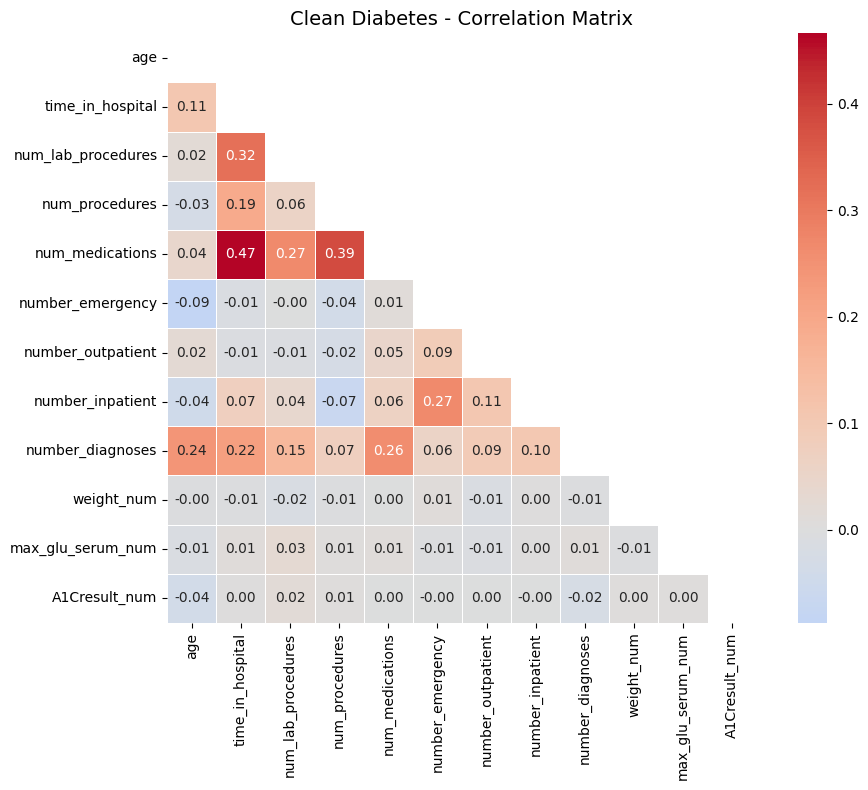

In [ ]:
plot_corr_heatmap(cleandiabetes, numerical, "Clean Diabetes - Correlation Matrix")


## Breaking the data up into Train & Test

In [ ]:
#@title Setting Up Data for Modeling 
#Uses the cleandiabetes dataset for modeling.
DataTesting = cleandiabetes.copy() #change it to sub2 or Sub3 to test each dataset

In [ ]:
# Step 1: Split cleandiabetes into Train (70%) and Temp (30%)
train_df, temp_df = train_test_split(
    DataTesting,
    test_size=0.30,        # 30% goes to temp (valid + test)
    random_state=42,       # ensures reproducibility
    shuffle=True           # shuffles before splitting
)


# Step 2: Split Temp into Validation (15%) and Test (15%)
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,        # half of temp = 15% of total
    random_state=42,
    shuffle=True
)

# Step 3: Reset indexes for cleanliness
train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)


# Step 4: Just Making Sure Check
print("Train size:", len(train_df))
print("Validation size:", len(valid_df))
print("Test size:", len(test_df))
print("Total:", len(train_df) + len(valid_df) + len(test_df))


Train size: 71236
Validation size: 15265
Test size: 15265
Total: 101766


In [ ]:
DataTesting.lessthan30.value_counts()

lessthan30
0    90409
1    11357
Name: count, dtype: int64

In [ ]:
train_df.lessthan30.value_counts()

lessthan30
0    63304
1     7932
Name: count, dtype: int64

In [ ]:
valid_df.lessthan30.value_counts()

lessthan30
0    13500
1     1765
Name: count, dtype: int64

In [ ]:
test_df.lessthan30.value_counts()

lessthan30
0    13605
1     1660
Name: count, dtype: int64

## Ways to Fix/Treat the Imbalance in the Data
Imbalance in the data means that one of the classes in the data is too less as compared to the others. Typically, it is better to balance the data in some way to give the positives more weight. There are 3 strategies that are typically utilized:

#### 1. RANDOM OVERSAMPLING: 
This technique involves randomly duplicating examples from the minority class in the training dataset. 
This can help balance the class distribution but may lead to overfitting since it replicates existing data points.

In [ ]:
def balance_random_oversample(df, target='readmit_less_30', random_state=42):
    df_pos = df[df[target] == 1]
    df_neg = df[df[target] == 0]

    df_pos_over = resample(
        df_pos,
        replace=True,
        n_samples=len(df_neg),
        random_state=random_state
    )

    df_bal = (
        pd.concat([df_neg, df_pos_over])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal

#### 2. SMOTE 
(Synthetic Minority Over-sampling Technique): SMOTE generates synthetic examples of the minority class by interpolating between existing minority class examples. 
This can help create a more balanced dataset without simply duplicating existing data points, which may reduce the risk of overfitting compared to random oversampling.

In [ ]:
def balance_smote(df, target='readmit_less_30', random_state=42):
    X = df.drop(columns=[target])
    y = df[target]

    sm = SMOTE(random_state=random_state)
    X_res, y_res = sm.fit_resample(X, y)

    df_bal = pd.concat(
        [pd.DataFrame(X_res, columns=X.columns),
         pd.Series(y_res, name=target)],
        axis=1
    )

    return df_bal

#### 3. RANDOM UNDERSAMPLING
Random Undersampling reduces the size of the majority class by randomly removing samples until it matches the minority class count. This creates a balanced dataset without generating synthetic data.

In [ ]:
def balance_random_undersample(df, target='readmit_less_30', random_state=42):
    df_pos = df[df[target] == 1]
    df_neg = df[df[target] == 0]

    df_neg_under = df_neg.sample(
        n=len(df_pos),
        random_state=random_state
    )

    df_bal = (
        pd.concat([df_pos, df_neg_under])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal

#### 4. SMOTEENN


In [ ]:
from imblearn.combine import SMOTEENN
from imblearn.over_sampling import SMOTE

def apply_smoteenn(X, y, k_neighbors=5, random_state=42):
    """
    Apply SMOTEENN hybrid resampling:
    - SMOTE oversamples the minority class
    - ENN removes noisy majority samples

    Returns:
        X_resampled, y_resampled
    """
    smote = SMOTE(k_neighbors=k_neighbors, random_state=random_state)
    smote_enn = SMOTEENN(smote=smote, random_state=random_state)

    X_resampled, y_resampled = smote_enn.fit_resample(X, y)
    return X_resampled, y_resampled

#### 5. SMOTETOMEK

In [ ]:
from imblearn.combine import SMOTETomek

def apply_smotetomek(X, y, k_neighbors=5, random_state=42):
    """
    Apply SMOTETomek hybrid resampling:
    - SMOTE oversamples the minority class
    - Tomek Links remove borderline/noisy majority samples

    Returns:
        X_resampled, y_resampled
    """
    smote = SMOTE(k_neighbors=k_neighbors, random_state=random_state)
    smote_tomek = SMOTETomek(smote=smote, random_state=random_state)

    X_resampled, y_resampled = smote_tomek.fit_resample(X, y)
    return X_resampled, y_resampled


#### Prevalence Caculation Function

In [ ]:
def calc_prevalence(y_actual):
    """
    Calculate the prevalence (ratio of positive class = 1)
    in a binary target array or Series.
    """
    y_actual = pd.Series(y_actual)
    return y_actual.mean()

<h2 style="color:#e63946;">CHANGE THE IMBALANCE TECHNIQUE HERE</h2>
“Remove the # to activate a specific technique."


In [ ]:
# 1. Split train_df into X and y
X_train = train_df.drop(columns=["lessthan30"])
y_train = train_df["lessthan30"]

# 2. Apply SMOTEENN
X_bal, y_bal = apply_smoteenn(X_train, y_train)

# 3. Combine back into a single DataFrame (optional)
train_balanced = X_bal.copy()
train_balanced["lessthan30"] = y_bal

# 4. Check prevalence
print(
    "Train balanced prevalence (n = %d): %.3f" %
    (len(train_balanced), calc_prevalence(train_balanced['lessthan30']))
)


ValueError: could not convert string to float: 'emergency'

In [ ]:
train_balanced.lessthan30.value_counts()

lessthan30
1    60760
0    34347
Name: count, dtype: int64

In [ ]:
X_train = train_balanced.drop('lessthan30',axis=1)

y_train = train_balanced['lessthan30']

X_valid = valid_df.drop('lessthan30',axis=1)

y_valid = valid_df['lessthan30']

X_test = test_df.drop('lessthan30',axis=1)

y_test = test_df['lessthan30']

<h2 style="color:#e63946;">CHANGE THE SETS HERE FOR SCALER</h2>

In [ ]:
scale_cols = numerical
# -----------------------------------------
# 1. Fit the scaler on TRAINING data only
# -----------------------------------------
scaler = StandardScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])

# -----------------------------------------
# 2. Transform VALIDATION and TEST sets
# -----------------------------------------
X_valid[scale_cols] = scaler.transform(X_valid[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])


In [ ]:
X_train.head()

,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,diabetesMed,...,diag_3_chapter,Race_Caucasian,Race_AfricanAmerican,Race_Unknown,Race_Other,Race_Asian,Race_Hispanic,weight_num,max_glu_serum_num,A1Cresult_num
0,1.219603,2.084699,0.085864,-0.731681,-0.269958,-0.270325,-0.208779,-0.546039,0.921860,1,...,1,1,0,0,0,0,0,-0.944127,-0.615964,-1.103549
1,-0.077116,-0.104713,-0.228469,-0.731681,-0.665314,-0.270325,-0.208779,-0.546039,-1.353531,0,...,1,1,0,0,0,0,0,1.484960,0.402120,0.764436
2,1.219603,-1.199418,-0.333247,0.611716,-1.192455,-0.270325,-0.208779,-0.546039,-1.353531,0,...,0,1,0,0,0,0,0,0.401928,0.523320,0.249129
3,-0.077116,1.354895,0.085864,-0.731681,1.047894,-0.270325,0.869841,2.342851,0.921860,1,...,1,1,0,0,0,0,0,-0.077701,0.789961,-0.201763
4,-0.077116,2.814503,0.400197,-0.731681,-0.533529,-0.270325,-0.208779,-0.546039,-0.215835,1,...,1,1,0,0,0,0,0,0.943444,1.008122,1.279742


In [ ]:
X_train.head().T

,0,1,2,3,4
age,1.219603,-0.077116,1.219603,-0.077116,-0.077116
time_in_hospital,2.084699,-0.104713,-1.199418,1.354895,2.814503
num_lab_procedures,0.085864,-0.228469,-0.333247,0.085864,0.400197
num_procedures,-0.731681,-0.731681,0.611716,-0.731681,-0.731681
num_medications,-0.269958,-0.665314,-1.192455,1.047894,-0.533529
number_outpatient,-0.270325,-0.270325,-0.270325,-0.270325,-0.270325
number_emergency,-0.208779,-0.208779,-0.208779,0.869841,-0.208779
number_inpatient,-0.546039,-0.546039,-0.546039,2.342851,-0.546039
number_diagnoses,0.921860,-1.353531,-1.353531,0.921860,-0.215835
diabetesMed,1.000000,0.000000,0.000000,1.000000,1.000000


## Creating and Understanding Models

In [ ]:
def calc_specificity(y_actual, y_pred, thresh):
    # calculates specificity
    return sum((y_pred < thresh) & (y_actual == 0)) /sum(y_actual ==0)

def print_report(y_actual, y_pred, thresh = 0.5):
    
    '''
    This function calculates all the metrics to asses the machine learning models.
    
    Params:
    1. y_actual: The actual values for the target variable.
    2. y_pred: The predicted values for the target variable.
    3. thresh: The threshold for the probability to be considered as a positive class. Default value 0.5
    
    Return:
    1. AUC - ROC Curve
    2. Accuracy
    3. Recall
    4. Precision
    5. Specificity
    '''
    
    auc = roc_auc_score(y_actual, y_pred)
    accuracy = accuracy_score(y_actual, (y_pred > thresh))
    recall = recall_score(y_actual, (y_pred > thresh))
    precision = precision_score(y_actual, (y_pred > thresh))
    specificity = calc_specificity(y_actual, y_pred, thresh)
    print('AUC:%.3f'%auc)
    print('accuracy:%.3f'%accuracy)
    print('recall:%.3f'%recall)
    print('precision:%.3f'%precision)
    print('specificity:%.3f'%specificity)
    print('prevalence:%.3f'%calc_prevalence(y_actual))
    print(' ')
    return auc, accuracy, recall, precision, specificity

### Linear Regression

In [ ]:
# disable truncation so NumPy prints the entire array
np.set_printoptions(threshold=np.inf)

lnr = LinearRegression()
lnr.fit(X_train, y_train)

y_valid_preds = lnr.predict(X_valid)

In [ ]:
print(y_valid_preds)

[ 5.57654010e-01  4.95149682e-01  3.37150745e-01  1.27893393e-01
  3.45813066e-01  5.77536276e-01  5.32413817e-01  5.38128501e-01
  2.67424227e-01  4.71721144e-01  4.73940660e-01  2.39098609e-01
  4.75836244e-01  5.29440000e-01  4.38827117e-01  3.26243345e-01
  4.28686650e-01  3.84467821e-01  5.48579902e-01  4.14284938e-01
  5.70006636e-01  6.56718315e-01  5.77314216e-01  4.45561124e-01
  4.27516268e-01  5.38597980e-01  2.57609616e-01  5.98613427e-01
  6.45436170e-01  5.56483750e-01  4.62970670e-01  2.54855058e-01
  3.84891434e-01  2.22835817e-01  4.36936618e-01  6.44213894e-01
  4.88174668e-01  5.88045832e-01  4.61417334e-01  5.88253782e-01
  4.71637495e-01  5.66764415e-01  4.53282083e-01  1.88224691e-01
  5.15219340e-01  4.04859216e-01  4.88619018e-01  4.05414302e-01
  4.39432283e-01  4.03128312e-01  3.76038449e-01  6.78028220e-01
  5.47290075e-01  4.40459471e-01  2.68338631e-01  5.16060560e-01
 -2.71049259e-02  1.21387827e-01  1.30568263e-01  6.67033735e-01
  4.16331291e-01  4.86281

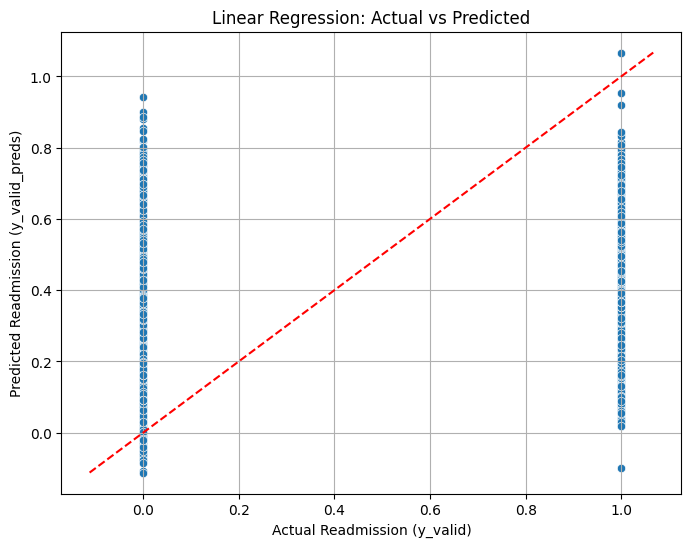

In [ ]:
# Create a scatter plot of Actual vs Predicted
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_valid, y=y_valid_preds)

# Add a 45-degree reference line
min_val = min(y_valid.min(), y_valid_preds.min())
max_val = max(y_valid.max(), y_valid_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.xlabel("Actual Readmission (y_valid)")
plt.ylabel("Predicted Readmission (y_valid_preds)")
plt.title("Linear Regression: Actual vs Predicted")
plt.grid(True)
plt.show()


### Logistic Regression

In [ ]:
lr=LogisticRegression(random_state = 42, solver = 'newton-cg', max_iter = 200)
lr.fit(X_train, y_train)

y_valid_preds = lr.predict_proba(X_valid)[:,1]

print('Metrics for Validation data:')

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,y_valid_preds, 0.5)

Metrics for Validation data:
AUC:0.561
accuracy:0.732
recall:0.282
precision:0.150
specificity:0.791
prevalence:0.116
 


### KNN Model

In [ ]:
knn = KNeighborsClassifier(n_neighbors = 100)
knn.fit(X_train, y_train)

knn_preds = knn.predict_proba(X_valid)[:,1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,knn_preds, 0.5)

AUC:0.581
accuracy:0.452
recall:0.678
precision:0.133
specificity:0.395
prevalence:0.116
 


### Stochastic Gradient Descent Model

In [ ]:
sgdc = SGDClassifier(loss='log_loss', alpha=0.1, random_state=42)
sgdc.fit(X_train, y_train)

sgd_preds = sgdc.predict_proba(X_valid)[:, 1]

print('Stochastic Gradient Descent')
print('Validation:')
sgdc_valid_auc, sgdc_valid_accuracy, sgdc_valid_recall, \
sgdc_valid_precision, sgdc_valid_specificity = print_report(y_valid, sgd_preds, 0.5)

Stochastic Gradient Descent
Validation:
AUC:0.574
accuracy:0.238
recall:0.895
precision:0.121
specificity:0.152
prevalence:0.116
 


### Decision Tree

In [ ]:
dc_clf = DecisionTreeClassifier(random_state=42, max_depth = 10)
dc_clf.fit(X_train, y_train)

dc_preds_proba = dc_clf.predict_proba(X_valid)[:,1]
dc_preds = dc_clf.predict(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,dc_preds_proba, 0.5)

AUC:0.563
accuracy:0.740
recall:0.261
precision:0.147
specificity:0.800
prevalence:0.116
 


### Random Forest

In [ ]:
rf_clf = RandomForestClassifier(random_state=111, max_depth = 4)

rf_clf.fit(X_train, y_train)

rf_preds = rf_clf.predict(X_valid)
rf_preds_proba = rf_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,rf_preds_proba, 0.5)

AUC:0.540
accuracy:0.302
recall:0.818
precision:0.123
specificity:0.235
prevalence:0.116
 


### Linear SVC

In [ ]:
lsvc_clf = LinearSVC(random_state=111)
lsvc_clf.fit(X_train, y_train)

lsvc_preds = lsvc_clf.decision_function(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,lsvc_preds, 0.5)

AUC:0.561
accuracy:0.879
recall:0.029
precision:0.279
specificity:0.990
prevalence:0.116
 


### Gradient Boosting Model

In [ ]:
gb_clf = GradientBoostingClassifier(n_estimators = 100, criterion='friedman_mse', learning_rate = 1.0, max_depth = 3,\
                                    random_state = 111)

gb_clf.fit(X_train, y_train)
gb_preds = gb_clf.predict(X_valid)
gb_preds_proba = gb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,gb_preds_proba, 0.5)

AUC:0.580
accuracy:0.797
recall:0.197
precision:0.172
specificity:0.875
prevalence:0.116
 


### XGB Model

In [ ]:
xgb_clf = xgb.XGBClassifier(max_depth=3, learning_rate = 1.0, use_label_encoder = False,\
                            eval_metric = 'logloss')
xgb_clf.fit(X_train, y_train)

xgb_preds = xgb_clf.predict(X_valid)
xgb_preds_proba = xgb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,xgb_preds_proba, 0.5)

AUC:0.585
accuracy:0.825
recall:0.147
precision:0.182
specificity:0.913
prevalence:0.116
 


### Catboost Model

In [ ]:
catb=CatBoostClassifier(iterations=200, depth=3, learning_rate=1.0, random_state = 111)
catb.fit(X_train, y_train)
catb_preds = catb.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,catb_preds, 0.5)

0:	learn: 0.4952323	total: 137ms	remaining: 27.3s
1:	learn: 0.4634423	total: 141ms	remaining: 14s
2:	learn: 0.4424837	total: 146ms	remaining: 9.56s
3:	learn: 0.4241904	total: 150ms	remaining: 7.36s
4:	learn: 0.4050082	total: 155ms	remaining: 6.06s
5:	learn: 0.3949650	total: 161ms	remaining: 5.21s
6:	learn: 0.3885835	total: 166ms	remaining: 4.59s
7:	learn: 0.3792862	total: 171ms	remaining: 4.1s
8:	learn: 0.3749579	total: 175ms	remaining: 3.71s
9:	learn: 0.3689973	total: 180ms	remaining: 3.41s
10:	learn: 0.3654302	total: 184ms	remaining: 3.17s
11:	learn: 0.3625607	total: 189ms	remaining: 2.96s
12:	learn: 0.3484026	total: 195ms	remaining: 2.81s
13:	learn: 0.3467835	total: 200ms	remaining: 2.66s
14:	learn: 0.3456157	total: 205ms	remaining: 2.53s
15:	learn: 0.3382249	total: 210ms	remaining: 2.41s
16:	learn: 0.3277835	total: 215ms	remaining: 2.31s
17:	learn: 0.3235333	total: 220ms	remaining: 2.22s
18:	learn: 0.3221582	total: 225ms	remaining: 2.14s
19:	learn: 0.3214408	total: 231ms	remaining:

## Hyper Parameter Tuning

### Decision Tree

In [ ]:
# Decision Tree - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

dc_grid = {'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'min_samples_leaf': range(1, 11, 2), ###  -->> Added a critical param
           'criterion':['gini','entropy']} # criterion for evaluating a split

dc_random = RandomizedSearchCV(estimator = dc_clf, param_distributions = dc_grid,
                               n_iter = 20,
                               cv = 10,              ### -->> chnaged cv from 2 to 5
                               scoring ='recall',   ### -->> changed fromscoring=recall_scoring,
                               verbose = 1, random_state = 111)

dc_random.fit(X_train, y_train)

dc_random.best_params_

dc_hp_preds = dc_random.best_estimator_.predict(X_valid)
dc_hp_preds_proba = dc_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, dc_hp_preds_proba)

# added later
print("Best params:", dc_random.best_params_)
print("Best CV recall:", dc_random.best_score_)
print("Validation recall:", recall_score(y_valid, dc_random.best_estimator_.predict(X_valid)))

"""
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params: {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}
Best CV recall: 0.8327703475995127
Validation recall: 0.996244131455399

add all metrics from above
"""

Fitting 10 folds for each of 20 candidates, totalling 200 fits
Best params: {'min_samples_split': 4, 'min_samples_leaf': 3, 'max_features': 'sqrt', 'max_depth': 4, 'criterion': 'gini'}
Best CV recall: 0.9520737327188942
Validation recall: 0.8441926345609065


"\nFitting 5 folds for each of 20 candidates, totalling 100 fits\nBest params: {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}\nBest CV recall: 0.8327703475995127\nValidation recall: 0.996244131455399\n\nadd all metrics from above\n"

In [ ]:

recall_score(y_valid, dc_hp_preds)

0.8441926345609065

### Random Forest

In [ ]:
# Random Forest - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

rf_grid = {'n_estimators':range(200,1000,200), # number of trees
           'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'criterion':['gini','entropy']} # criterion for evaluating a split

rf_random = RandomizedSearchCV(estimator = rf_clf, param_distributions = rf_grid,
                               n_iter = 20, cv = 2, scoring=recall_scoring,
                               verbose = 1, random_state = 111)

rf_random.fit(X_train, y_train)

rf_random.best_params_

rf_hp_preds = rf_random.best_estimator_.predict(X_valid)
rf_hp_preds_proba = rf_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, rf_hp_preds_proba)

Fitting 2 folds for each of 20 candidates, totalling 40 fits


0.517703011226524

In [ ]:

recall_score(y_valid, dc_hp_preds)

0.8441926345609065

### XGBoost

In [ ]:
#xgboost - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

xgb_grid = params = {
        'min_child_weight': [1, 5, 8, 10],
        'gamma': [0.5, 1, 1.5, 2, 5],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 0.9, 1.0],
        'max_depth': [3, 4, 5]
        } # criterion for evaluating a split

xgb_random = GridSearchCV(estimator = xgb_clf, param_grid = xgb_grid,
                               cv = 2, scoring = recall_scoring,
                               verbose = 1)

xgb_random.fit(X_train, y_train)

xgb_random.best_params_

xgb_hp_preds = xgb_random.best_estimator_.predict(X_valid)
xgb_hp_preds_proba = xgb_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, xgb_hp_preds_proba)

Fitting 2 folds for each of 720 candidates, totalling 1440 fits


0.5710594691008288

In [ ]:

recall_score(y_valid, dc_hp_preds)

0.8441926345609065

In [ ]:
print(cleandiabetes.head())

   age  time_in_hospital  num_lab_procedures  num_procedures  num_medications  \
0    5                 1                  41               0                1   
1   15                 3                  59               0               18   
2   25                 2                  11               5               13   
3   35                 2                  44               1               16   
4   45                 1                  51               0                8   

   number_outpatient  number_emergency  number_inpatient  number_diagnoses  \
0                  0                 0                 0                 1   
1                  0                 0                 0                 9   
2                  2                 0                 1                 6   
3                  0                 0                 0                 7   
4                  0                 0                 0                 5   

   diabetesMed  ...  lessthan30  Race_Caucas

#### 4. SAVING PKL MODEL

In [ ]:
import joblib
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, recall_score, precision_score, accuracy_score, confusion_matrix

# ============================================================
# TARGET
# ============================================================
target = "lessthan30"

print("\n" + "="*70)
print(f"     RANDOM FOREST — FINAL MODEL ({target.upper()}) ")
print("="*70)

prev = y_valid.mean()

# ============================================================
# TRAIN RANDOM FOREST
# ============================================================
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    min_samples_split=2,
    random_state=111,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# ============================================================
# PREDICT PROBABILITIES
# ============================================================
preds_proba = rf.predict_proba(X_valid)[:, 1]

# ============================================================
# METRICS
# ============================================================
auc = roc_auc_score(y_valid, preds_proba)

preds = (preds_proba >= 0.5).astype(int)

acc = accuracy_score(y_valid, preds)
rec = recall_score(y_valid, preds)
prec = precision_score(y_valid, preds)

tn, fp, fn, tp = confusion_matrix(y_valid, preds).ravel()
spec = tn / (tn + fp)

# ============================================================
# PRINT RESULTS
# ============================================================
print("\nValidation Metrics (Random Forest):")
print("-"*50)
print(f"AUC:          {auc:.4f}")
print(f"Accuracy:     {acc:.4f}")
print(f"Recall:       {rec:.4f}")
print(f"Precision:    {prec:.4f}")
print(f"Specificity:  {spec:.4f}")
print(f"Prevalence:   {prev:.4f}")
print("="*70)

# ============================================================
# SAVE MODEL
# ============================================================
filename = f"{target}_RandomForest_Tuned.Smoteenn.Imputations.pkl"
joblib.dump(rf_random.best_estimator_, filename)

print(f"Saved Tuned Random Forest model as '{filename}'")
print("="*70 + "\n")

final_models = {target: rf_random.best_estimator_}



     RANDOM FOREST — FINAL MODEL (LESSTHAN30) 

Validation Metrics (Random Forest):
--------------------------------------------------
AUC:          0.5565
Accuracy:     0.4901
Recall:       0.6023
Precision:    0.1305
Specificity:  0.4755
Prevalence:   0.1156
Saved Tuned Random Forest model as 'lessthan30_RandomForest_Tuned.Smoteenn.Imputations.pkl'



In [ ]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score

def binarize(preds, threshold=0.5):
    return (preds >= threshold).astype(int)

results = []

# Logistic Regression
results.append([
    "Logistic Regression",
    roc_auc_score(y_valid, y_valid_preds),
    accuracy_score(y_valid, binarize(y_valid_preds)),
    recall_score(y_valid, binarize(y_valid_preds)),
    precision_score(y_valid, binarize(y_valid_preds)),
    recall_score(y_valid, binarize(y_valid_preds), pos_label=0)
])

# KNN
results.append([
    "KNN",
    roc_auc_score(y_valid, knn_preds),
    accuracy_score(y_valid, binarize(knn_preds)),
    recall_score(y_valid, binarize(knn_preds)),
    precision_score(y_valid, binarize(knn_preds)),
    recall_score(y_valid, binarize(knn_preds), pos_label=0)
])

# SGDClassifier
results.append([
    "SGDClassifier",
    roc_auc_score(y_valid, sgd_preds),
    accuracy_score(y_valid, binarize(sgd_preds)),
    recall_score(y_valid, binarize(sgd_preds)),
    precision_score(y_valid, binarize(sgd_preds)),
    recall_score(y_valid, binarize(sgd_preds), pos_label=0)
])

# Decision Tree
results.append([
    "Decision Tree",
    roc_auc_score(y_valid, dc_preds_proba),
    accuracy_score(y_valid, dc_preds),
    recall_score(y_valid, dc_preds),
    precision_score(y_valid, dc_preds),
    recall_score(y_valid, dc_preds, pos_label=0)
])

# Random Forest
results.append([
    "Random Forest",
    roc_auc_score(y_valid, rf_preds_proba),
    accuracy_score(y_valid, rf_preds),
    recall_score(y_valid, rf_preds),
    precision_score(y_valid, rf_preds),
    recall_score(y_valid, rf_preds, pos_label=0)
])

# Linear SVC
results.append([
    "Linear SVC",
    roc_auc_score(y_valid, lsvc_preds),
    accuracy_score(y_valid, binarize(lsvc_preds, threshold=0)),
    recall_score(y_valid, binarize(lsvc_preds, threshold=0)),
    precision_score(y_valid, binarize(lsvc_preds, threshold=0)),
    recall_score(y_valid, binarize(lsvc_preds, threshold=0), pos_label=0)
])

# Gradient Boosting
results.append([
    "Gradient Boosting",
    roc_auc_score(y_valid, gb_preds_proba),
    accuracy_score(y_valid, gb_preds),
    recall_score(y_valid, gb_preds),
    precision_score(y_valid, gb_preds),
    recall_score(y_valid, gb_preds, pos_label=0)
])

# XGBoost
results.append([
    "XGBoost",
    roc_auc_score(y_valid, xgb_preds_proba),
    accuracy_score(y_valid, xgb_preds),
    recall_score(y_valid, xgb_preds),
    precision_score(y_valid, xgb_preds),
    recall_score(y_valid, xgb_preds, pos_label=0)
])

# CatBoost
results.append([
    "CatBoost",
    roc_auc_score(y_valid, catb_preds),
    accuracy_score(y_valid, binarize(catb_preds)),
    recall_score(y_valid, binarize(catb_preds)),
    precision_score(y_valid, binarize(catb_preds)),
    recall_score(y_valid, binarize(catb_preds), pos_label=0)
])

# Decision Tree (HP Tuned)
results.append([
    "Decision Tree (HP Tuned)",
    roc_auc_score(y_valid, dc_hp_preds_proba),
    accuracy_score(y_valid, dc_hp_preds),
    recall_score(y_valid, dc_hp_preds),
    precision_score(y_valid, dc_hp_preds),
    recall_score(y_valid, dc_hp_preds, pos_label=0)
])

# Random Forest (HP Tuned)
results.append([
    "Random Forest (HP Tuned)",
    roc_auc_score(y_valid, rf_hp_preds_proba),
    accuracy_score(y_valid, rf_hp_preds),
    recall_score(y_valid, rf_hp_preds),
    precision_score(y_valid, rf_hp_preds),
    recall_score(y_valid, rf_hp_preds, pos_label=0)
])

# XGBoost (HP Tuned)
results.append([
    "XGBoost (HP Tuned)",
    roc_auc_score(y_valid, xgb_hp_preds_proba),
    accuracy_score(y_valid, xgb_hp_preds),
    recall_score(y_valid, xgb_hp_preds),
    precision_score(y_valid, xgb_hp_preds),
    recall_score(y_valid, xgb_hp_preds, pos_label=0)
])

results_df = pd.DataFrame(results, columns=["Model", "AUC", "Accuracy", "Recall", "Precision", "Specificity"])
results_df


,Model,AUC,Accuracy,Recall,Precision,Specificity
0,Logistic Regression,0.560793,0.732067,0.281586,0.149744,0.790963
1,KNN,0.581187,0.430593,0.699717,0.131425,0.395407
2,SGDClassifier,0.574477,0.238061,0.894618,0.121238,0.152222
3,Decision Tree,0.562873,0.739993,0.261190,0.147473,0.802593
4,Random Forest,0.540430,0.302260,0.817564,0.122579,0.234889
5,Linear SVC,0.560645,0.735932,0.275921,0.150309,0.796074
6,Gradient Boosting,0.579855,0.797052,0.197167,0.171513,0.875481
7,XGBoost,0.585286,0.824763,0.147309,0.181818,0.913333
8,CatBoost,0.610450,0.869833,0.066856,0.257642,0.974815
9,Decision Tree (HP Tuned),0.522547,0.256600,0.844193,0.118602,0.179778
